In [3]:
import matplotlib.pyplot as plt

Download a sample sales dataset (for example, from Kaggle or use a small CSV you create) with columns like product, category, date, and sales amount. Load it into a Pandas DataFrame and display the first 5 rows to verify the data.

In [1]:
import pandas as pd
import io

# Simulated CSV sales data string (representing a real dataset file)
csv_data = """order_id,date,category,product,sales_amount
101,2026-10-01,Electronics,Smartphone,45000
102,2026-10-01,Apparel,Saree,3500
103,2026-10-02,Electronics,Wireless Earbuds,2500
104,2026-10-03,Home & Kitchen,Mixer Grinder,4200
105,2026-10-03,Apparel,Kurti Set,1800
106,2026-10-04,Electronics,Smartwatch,6000
107,2026-10-05,Home & Kitchen,Bedsheet Set,1500
"""

# Load the CSV data into a Pandas DataFrame
# (For a local file, use: df = pd.read_csv('your_file.csv'))
df = pd.read_csv(io.StringIO(csv_data))

# Display the first 5 rows to verify the loaded data structure
print("--- First 5 Rows of the Sales Dataset ---")
print(df.head())

--- First 5 Rows of the Sales Dataset ---
   order_id        date        category           product  sales_amount
0       101  2026-10-01     Electronics        Smartphone         45000
1       102  2026-10-01         Apparel             Saree          3500
2       103  2026-10-02     Electronics  Wireless Earbuds          2500
3       104  2026-10-03  Home & Kitchen     Mixer Grinder          4200
4       105  2026-10-03         Apparel         Kurti Set          1800


Using Matplotlib, create a bar chart that shows total sales for each product category (like 'Electronics', 'Clothing', 'Groceries'), similar to how Flipkart or Myntra might track category performance.


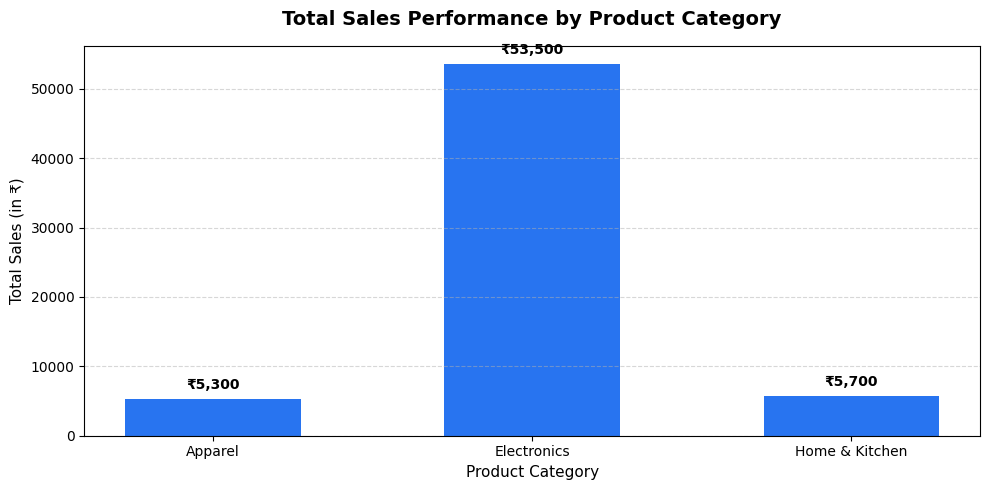

In [4]:
category_sales = df.groupby('category')['sales_amount'].sum().reset_index()

# Set up the figure size
plt.figure(figsize=(10, 5))

# Plot the bar chart using e-commerce blue (#2874F0)
bars = plt.bar(
    category_sales['category'], 
    category_sales['sales_amount'], 
    color='#2874F0', 
    width=0.55
)

# Add exact sales value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2, 
        yval + 1000, 
        f'₹{yval:,.0f}', 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold'
    )

# Add titles and axes labels
plt.title('Total Sales Performance by Product Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product Category', fontsize=11)
plt.ylabel('Total Sales (in ₹)', fontsize=11)

# Add a horizontal grid for readability
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Adjust layout to prevent label clipping
plt.tight_layout()

# Display the chart
plt.show()

Create a pie chart representing the percentage of different payment methods (UPI, Card, Wallet, Cash) used on an e-commerce app (like Flipkart), and add a legend positioned at the lower right corner of the plot.

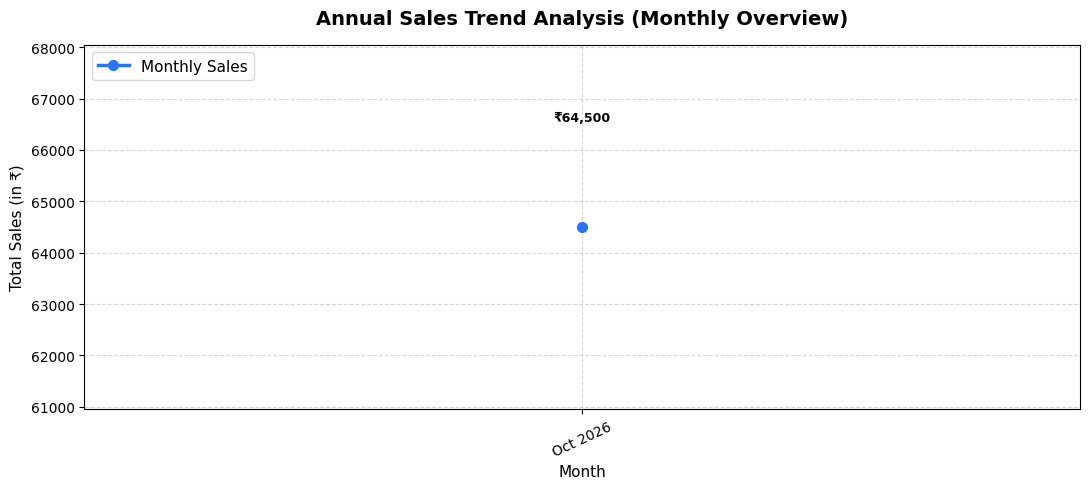

In [5]:
df['date'] = pd.to_datetime(df['date'])

# 3. Group by month to calculate total monthly sales
df['month_period'] = df['date'].dt.to_period('M')
monthly_sales = df.groupby('month_period')['sales_amount'].sum().reset_index()

# Convert the period back to formatted strings for clean chronological plotting
monthly_sales['month_str'] = monthly_sales['month_period'].dt.strftime('%b %Y')

# 4. Set up the presentation figure size
plt.figure(figsize=(11, 5))

# Plot the monthly trend line
plt.plot(
    monthly_sales['month_str'], 
    monthly_sales['sales_amount'], 
    marker='o', 
    color='#2874F0', 
    linewidth=2.5, 
    markersize=7, 
    label='Monthly Sales'
)

# Add exact sales value labels above each data point for executive polish
for x, y in zip(monthly_sales['month_str'], monthly_sales['sales_amount']):
    plt.text(
        x, 
        y + 2000, 
        f'₹{y:,.0f}', 
        ha='center', 
        va='bottom', 
        fontsize=9, 
        fontweight='bold'
    )

# 5. Add presentation-ready title and axis labels
plt.title('Annual Sales Trend Analysis (Monthly Overview)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=11)
plt.ylabel('Total Sales (in ₹)', fontsize=11)

# Add grid and legend
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11, frameon=True)

# Rotate x-axis date labels slightly for optimal readability
plt.xticks(rotation=25)

# Adjust layout to prevent clipping
plt.tight_layout()

# Display the chart
plt.show()

Create a histogram to show the distribution of order amounts (sales values), highlighting how many small vs. large purchases happen — like analyzing order size patterns on Zomato or Swiggy.<br><br><em><strong>Hint:</strong> Use plt.hist() and set bins to 10 for a clear distribution.</em>

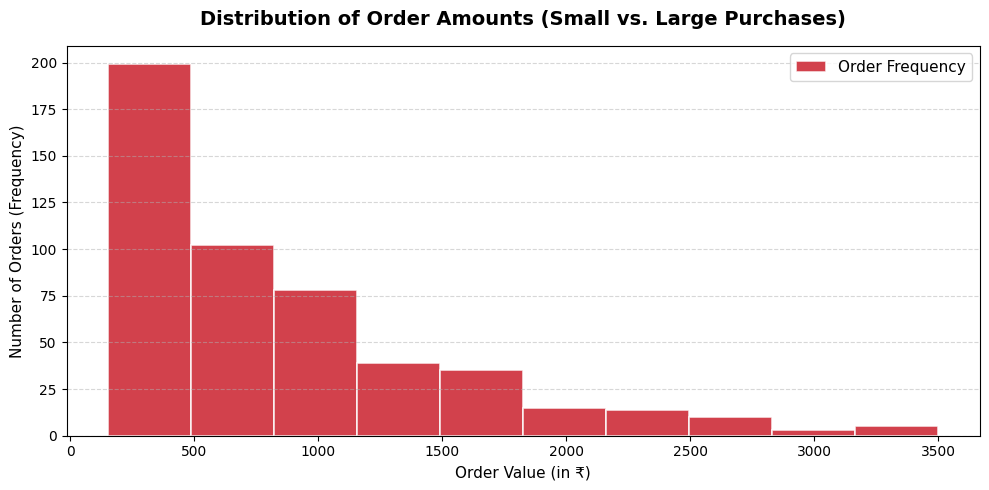

In [6]:
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Simulate 500 order amounts (in INR) skewed towards smaller/medium purchases
# Typical food delivery orders ranging from ₹150 to ₹3,500
order_amounts = np.random.exponential(scale=700, size=500) + 150
order_amounts = np.clip(order_amounts, 150, 3500)

# Set the figure size
plt.figure(figsize=(10, 5))

# Plot the histogram with 10 bins using Zomato crimson red
n, bins, patches = plt.hist(
    order_amounts, 
    bins=10, 
    color='#CB202D', 
    edgecolor='white', 
    linewidth=1.2, 
    alpha=0.85,
    label='Order Frequency'
)

# Add titles and axes labels
plt.title('Distribution of Order Amounts (Small vs. Large Purchases)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Order Value (in ₹)', fontsize=11)
plt.ylabel('Number of Orders (Frequency)', fontsize=11)

# Add a grid along the y-axis for readability
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add a legend
plt.legend(loc='upper right', fontsize=11, frameon=True)

# Adjust layout to prevent clipping
plt.tight_layout()

# Display the chart
plt.show()

Add value annotations to your category bar chart to display the exact sales amount above each bar, then export the chart as a PNG image file named 'category_sales_kpi.png'.

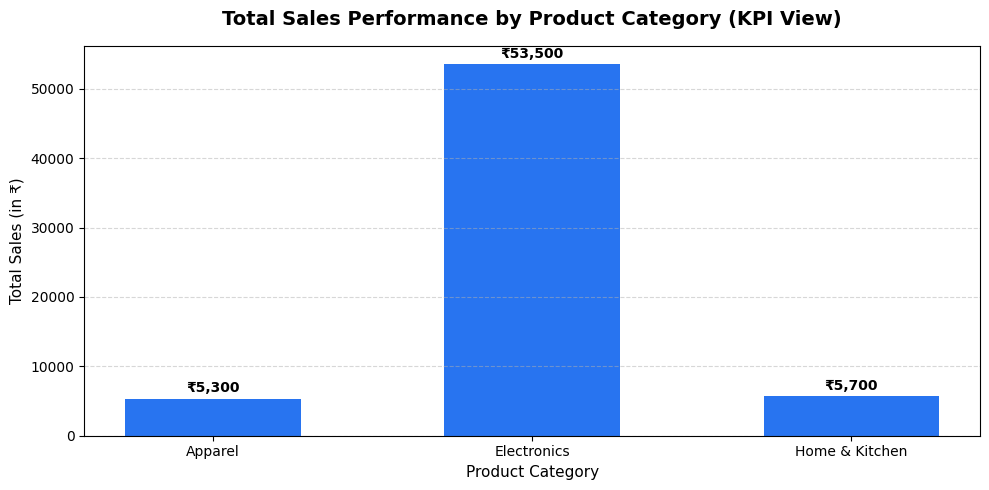

In [7]:
category_sales = df.groupby('category')['sales_amount'].sum().reset_index()

# Set up the figure size
plt.figure(figsize=(10, 5))

# Plot the bar chart using e-commerce blue (#2874F0)
bars = plt.bar(
    category_sales['category'], 
    category_sales['sales_amount'], 
    color='#2874F0', 
    width=0.55
)

# Add exact sales value annotations on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2, 
        yval + 500, 
        f'₹{yval:,.0f}', 
        ha='center', 
        va='bottom', 
        fontsize=10, 
        fontweight='bold'
    )

# Add titles and axes labels
plt.title('Total Sales Performance by Product Category (KPI View)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product Category', fontsize=11)
plt.ylabel('Total Sales (in ₹)', fontsize=11)

# Add a horizontal grid for readability
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Adjust layout to prevent label clipping
plt.tight_layout()

# Export the chart as a PNG image file named 'category_sales_kpi.png'
plt.savefig('category_sales_kpi.png', dpi=150, bbox_inches='tight')

# Display the chart
plt.show()